In [22]:
import pandas as pd
import openml
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
%matplotlib inline

In [23]:

import pandas as pd
from sklearn.datasets import fetch_openml

# Fetch dataset 43801 directly from OpenML via ID

# 'as_frame=True' forces scikit-learn to parse the ARFF file directly into a clean Pandas DataFrame
print("Downloading and parsing data...")
oml_data = fetch_openml(data_id=43801, as_frame=True, parser="auto")

# Extract the DataFrame
df = oml_data.frame

df




,name,selling_price,year,seller_type,owner,km_driven,ex_showroom_price
0,'Royal Enfield Classic 350',175000,2019,Individual,'1st owner',350,NaN
1,'Honda Dio',45000,2017,Individual,'1st owner',5650,NaN
2,'Royal Enfield Classic Gunmetal Grey',150000,2018,Individual,'1st owner',12000,148114.0
3,'Yamaha Fazer FI V 2.0 [2016-2018]',65000,2015,Individual,'1st owner',23000,89643.0
4,'Yamaha SZ [2013-2014]',20000,2011,Individual,'2nd owner',21000,NaN
...,...,...,...,...,...,...,...
1056,'Activa 3g',17000,2010,Individual,'1st owner',500000,52000.0
1057,'Honda CB twister',16000,2012,Individual,'1st owner',33000,51000.0
1058,'Bajaj Discover 125',15000,2013,Individual,'2nd owner',35000,57000.0
1059,'Honda CB Shine',12000,2009,Individual,'1st owner',53000,58000.0


In [24]:
print(df.head)# extracting the first five rows of the dataset
print(df.shape)# checking the shape of the data
print(df.describe())#statistical analysis of the data
df.to_dict(orient ='records')# converting the dataframe to dictionary 
df.isnull().sum() # checking Missing values


<bound method NDFrame.head of                                        name  selling_price  year seller_type  \
0               'Royal Enfield Classic 350'         175000  2019  Individual   
1                               'Honda Dio'          45000  2017  Individual   
2     'Royal Enfield Classic Gunmetal Grey'         150000  2018  Individual   
3       'Yamaha Fazer FI V 2.0 [2016-2018]'          65000  2015  Individual   
4                   'Yamaha SZ [2013-2014]'          20000  2011  Individual   
...                                     ...            ...   ...         ...   
1056                            'Activa 3g'          17000  2010  Individual   
1057                     'Honda CB twister'          16000  2012  Individual   
1058                   'Bajaj Discover 125'          15000  2013  Individual   
1059                       'Honda CB Shine'          12000  2009  Individual   
1060                     'Bajaj Pulsar 150'          10000  2008  Individual   

         

name                   0
selling_price          0
year                   0
seller_type            0
owner                  0
km_driven              0
ex_showroom_price    435
dtype: int64

In [25]:
# finding unique data in the frame
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()
    
    

name
<ArrowStringArray>
[          ''Royal Enfield Classic 350'',
                           ''Honda Dio'',
 ''Royal Enfield Classic Gunmetal Grey'',
   ''Yamaha Fazer FI V 2.0 [2016-2018]'',
               ''Yamaha SZ [2013-2014]'']
Length: 5, dtype: str
279

selling_price
[175000  45000 150000  65000  20000]
130

year
[2019 2017 2018 2015 2011]
28

seller_type
<ArrowStringArray>
['Individual', 'Dealer']
Length: 2, dtype: str
2

owner
<ArrowStringArray>
[''1st owner'', ''2nd owner'', ''3rd owner'', ''4th owner'']
Length: 4, dtype: str
4

km_driven
[  350  5650 12000 23000 21000]
304

ex_showroom_price
[    nan 148114.  89643.  53857.  87719.]
230



<Axes: xlabel='selling_price', ylabel='Count'>

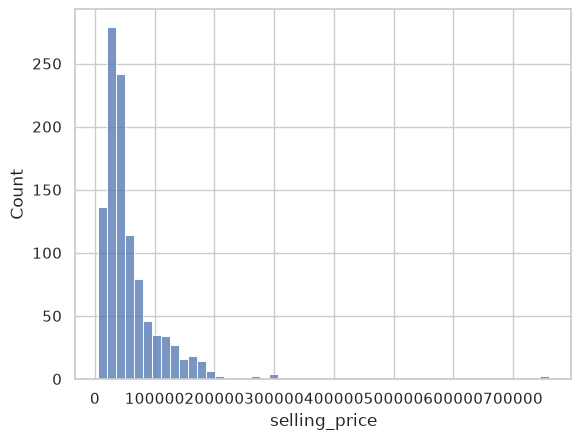

In [26]:
# distributon of the selling  price 
sns.histplot(df.selling_price, bins = 50)



<Axes: xlabel='selling_price', ylabel='Count'>

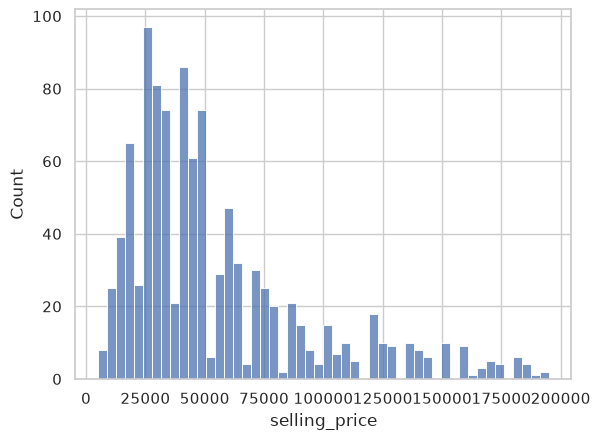

In [27]:
# prices less than $200,000
sns.histplot(df.selling_price[df.selling_price < 200000], bins = 50)

<Axes: xlabel='selling_price', ylabel='Count'>

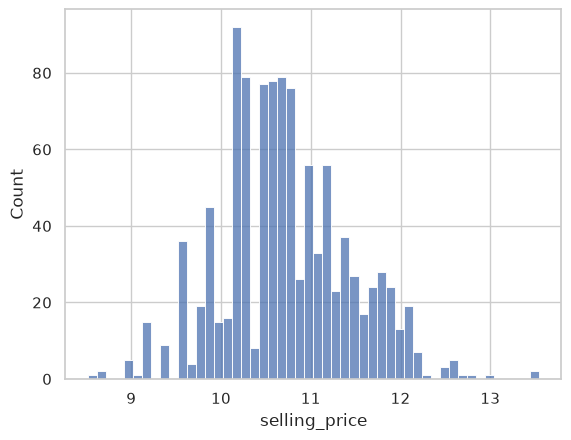

In [28]:
#normalizing the distribution using np.log
selling_price= np.log1p(df.selling_price)
sns.histplot(selling_price, bins= 50)

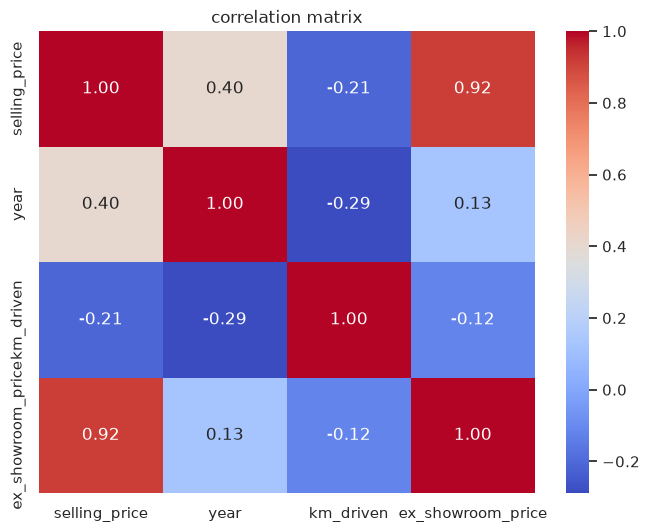

In [29]:
# checkig correlation between all numerical values 

plt.figure (figsize=(8,6))
sns.heatmap(df.corr(numeric_only =True),annot = True, cmap ='coolwarm' , fmt ='.2f')
plt.title('correlation matrix')
plt.show()
          